# ISB-CGC Community Notebooks

Check out more notebooks at our [Community Notebooks Repository](https://github.com/isb-cgc/Community-Notebooks)!

```
Title:   How to join IDC images with GDC clinical data
Author:  Aaron Kanzer (Scigantic), aaron@scigantic.com
Created: 2026-11-03
Purpose: Join Imaging Data Commons (IDC) DICOM metadata with Genomic Data Commons (GDC) clinical data in BigQuery, then read the matching CT series and whole slide image from the public IDC bucket
URL:     https://github.com/isb-cgc/Community-Notebooks/blob/master/Notebooks/How_to_join_IDC_images_with_GDC_clinical_data.ipynb
Notes:   Runs in Google Colab. The BigQuery steps need a Google Cloud project. The image reads need no credentials at all.
```
***

<a href="https://colab.research.google.com/github/isb-cgc/Community-Notebooks/blob/master/Notebooks/How_to_join_IDC_images_with_GDC_clinical_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# How to join IDC images with GDC clinical data

The NCI Cancer Research Data Commons keeps images and clinical records in different repositories. The [Imaging Data Commons (IDC)](https://imaging.datacommons.cancer.gov/) holds DICOM radiology and pathology images, and the [Genomic Data Commons (GDC)](https://portal.gdc.cancer.gov/) holds the clinical records for many of the same patients. For TCGA the two share a key: the IDC `PatientID` is the 12 character TCGA barcode, which is the GDC `submitter_id` in the ISB-CGC clinical tables.

In this notebook we will:

1. Count what imaging IDC holds for one GDC project (TCGA-LUAD, lung adenocarcinoma).
2. Join the IDC metadata to the GDC clinical tables and tabulate tumor stage against imaging availability.
3. Pick one patient who has a CT scan, a pathology slide, and a clinical record.
4. Read that patient's CT series and the lowest resolution level of a whole slide image directly from the public IDC bucket, with no credentials, and display them next to the clinical record.

Tables used in this notebook:

- `bigquery-public-data.idc_current.dicom_all`: one row per DICOM instance, maintained by IDC. The table is clustered on `collection_id`, so filtering by collection keeps the bytes scanned small (a few megabytes for one TCGA collection).
- `isb-cgc-bq.TCGA.clinical_gdc_current`: one row per GDC case.
- `isb-cgc-bq.TCGA.clinical_diagnosis_gdc_current`: one row per diagnosis, so a case can have more than one row.

More on these tables: [ISB-CGC BigQuery Tables](https://isb-cancer-genomics-cloud.readthedocs.io/en/latest/sections/BigQuery.html) and the [IDC BigQuery documentation](https://learn.canceridc.dev/data/organization-of-data/).

## Initialize Notebook Environment

Before beginning, we first need to load dependencies and authenticate to BigQuery. You will need to have access to a [Google Cloud Platform (GCP)](https://cloud.google.com/) project in order to use BigQuery. The image reading steps later on use anonymous access to the public IDC bucket on AWS and need no account of any kind.

### Install Dependencies

In [1]:
# pydicom reads DICOM files, pylibjpeg decodes the JPEG 2000 slide tiles, boto3 reads the public bucket.
# These are not preinstalled in Colab.
try:
    import pydicom, pylibjpeg, boto3
except ImportError:
    !pip install -q pydicom pylibjpeg pylibjpeg-openjpeg pylibjpeg-libjpeg boto3

In [2]:
import io
from concurrent.futures import ThreadPoolExecutor

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom
from botocore import UNSIGNED
from botocore.config import Config
from google.cloud import bigquery
from pydicom.pixels import pixel_array
from scipy import ndimage

pd.set_option("display.max_colwidth", 80)

### Authenticate

In order to use BigQuery, we must obtain authorization to BigQuery and Google Cloud. If you are running in Google Colab, the first cell below opens a sign in prompt. If you are running locally, comment it out and run `gcloud auth application-default login` in a terminal instead.

[Alternative authentication methods](https://googleapis.github.io/google-cloud-python/latest/core/auth.html)

In [3]:
# If you are using Google Colab, authenticate to gcloud with the following
try:
    from google.colab import auth
    auth.authenticate_user()
except ImportError:
    pass  # not in Colab: use `gcloud auth application-default login` instead

In [4]:
# Set the Google project that will be billed for this notebook's queries
google_project = 'my-project'  # replace with your project id

# Create a client to access the data within BigQuery
client = bigquery.Client(google_project)

def run_query(sql):
    return client.query(sql).to_dataframe()

## 1. What imaging does IDC hold for TCGA-LUAD?

IDC names its collections in lower case with underscores, so the GDC project `TCGA-LUAD` is the IDC collection `tcga_luad`. Every other TCGA project follows the same pattern, so you can change the two variables below to any TCGA project.

`dicom_all` has one row per DICOM instance (one CT slice, one slide pyramid level, one segmentation object). Grouping by `Modality` tells us what kinds of images exist and how many patients have each kind.

In [5]:
gdc_project = 'TCGA-LUAD'
collection_id = 'tcga_luad'

modalities = run_query(f'''
SELECT Modality,
  COUNT(DISTINCT PatientID) AS patients,
  COUNT(DISTINCT SeriesInstanceUID) AS series,
  COUNT(*) AS instances,
  ROUND(SUM(instance_size) / 1e9, 1) AS gigabytes
FROM `bigquery-public-data.idc_current.dicom_all`
WHERE collection_id = '{collection_id}'
GROUP BY Modality
ORDER BY patients DESC
''')
modalities

,Modality,patients,series,instances,gigabytes
0,SM,522,1608,7031,646.3
1,SEG,489,2075,4115,451.2
2,ANN,478,541,541,162.1
3,CT,67,551,35738,19.1
4,PT,23,66,13186,0.5
5,NM,2,7,7,0.0


`SM` is slide microscopy (whole slide images). `SEG` and `ANN` are analysis results that other groups derived from the images and contributed back to IDC, such as nuclei segmentations and annotations. The radiology (`CT`, `PT`, `NM`) covers far fewer patients than the pathology.

## 2. Join IDC metadata to GDC clinical data

The join key is `dicom_all.PatientID = clinical_gdc_current.submitter_id`. Tumor stage lives in the diagnosis table, which can hold several rows per case (for example a second row for a recurrence), so we keep the row flagged `diag__diagnosis_is_primary_disease`.

The query below starts from every GDC case in the project and left joins the imaging, so cases without images are still counted.

In [6]:
stage_by_imaging = run_query(f'''
WITH idc AS (
  SELECT PatientID,
    LOGICAL_OR(Modality = 'CT') AS has_ct,
    LOGICAL_OR(Modality = 'SM') AS has_slide
  FROM `bigquery-public-data.idc_current.dicom_all`
  WHERE collection_id = '{collection_id}'
  GROUP BY PatientID
),
clinical AS (
  SELECT c.submitter_id, d.diag__ajcc_pathologic_stage AS stage
  FROM `isb-cgc-bq.TCGA.clinical_gdc_current` AS c
  JOIN `isb-cgc-bq.TCGA.clinical_diagnosis_gdc_current` AS d
    ON d.case_id = c.case_id AND d.diag__diagnosis_is_primary_disease
  WHERE c.proj__project_id = '{gdc_project}'
)
SELECT IFNULL(stage, '(not reported)') AS stage,
  COUNT(*) AS gdc_cases,
  COUNTIF(idc.PatientID IS NOT NULL) AS in_idc,
  COUNTIF(has_slide) AS with_slides,
  COUNTIF(has_ct) AS with_ct,
  COUNTIF(has_ct AND has_slide) AS with_both
FROM clinical
LEFT JOIN idc ON idc.PatientID = clinical.submitter_id
GROUP BY stage
ORDER BY stage
''')
stage_by_imaging

,stage,gdc_cases,in_idc,with_slides,with_ct,with_both
0,(not reported),8,8,8,2,2
1,Stage I,5,5,5,1,1
2,Stage IA,134,134,134,7,7
3,Stage IB,140,140,140,5,5
4,Stage II,1,1,1,0,0
5,Stage IIA,50,50,50,1,1
6,Stage IIB,73,73,73,3,3
7,Stage IIIA,74,74,74,8,8
8,Stage IIIB,11,11,11,1,1
9,Stage IV,26,26,26,1,1


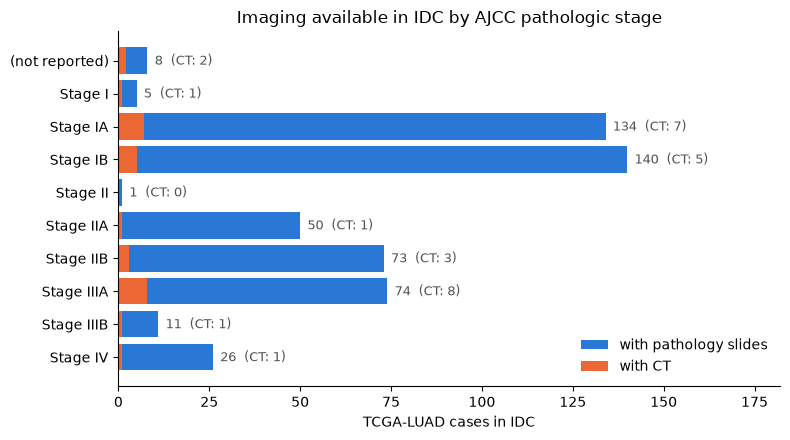

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(stage_by_imaging))
ax.barh(y, stage_by_imaging.with_slides, color='#2a78d6', label='with pathology slides')
ax.barh(y, stage_by_imaging.with_ct, color='#eb6834', label='with CT')
for yi, total, ct in zip(y, stage_by_imaging.with_slides, stage_by_imaging.with_ct):
    ax.text(total + 2, yi, f'{total}  (CT: {ct})', va='center', fontsize=9, color='#52514e')
ax.set_yticks(y)
ax.set_yticklabels(stage_by_imaging.stage)
ax.invert_yaxis()
ax.set_xlim(0, stage_by_imaging.with_slides.max() * 1.3)
ax.set_xlabel(f'{gdc_project} cases in IDC')
ax.set_title('Imaging available in IDC by AJCC pathologic stage')
ax.legend(frameon=False, loc='lower right')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()

Every GDC case in this project has at least one slide in IDC, and only a small subset has CT. Any imaging study that needs both modalities is therefore limited to that subset, which the next step lists.

## 3. Choose a patient

We list the patients who have both a CT series and a slide, with a few clinical fields, and sort them by the size of their CT data so a small example comes first. `ImageType` is an array in `dicom_all`; the `AXIAL` flag separates real axial scans from localizer images.

In [8]:
patients = run_query(f'''
WITH series AS (
  SELECT PatientID, Modality, SeriesInstanceUID,
    COUNT(*) AS n_instances,
    SUM(instance_size) / 1e6 AS megabytes,
    LOGICAL_OR('AXIAL' IN UNNEST(ImageType)) AS axial
  FROM `bigquery-public-data.idc_current.dicom_all`
  WHERE collection_id = '{collection_id}' AND Modality IN ('CT', 'SM')
  GROUP BY PatientID, Modality, SeriesInstanceUID
),
per_patient AS (
  SELECT PatientID,
    COUNTIF(Modality = 'CT' AND axial) AS axial_ct_series,
    COUNTIF(Modality = 'SM') AS slides,
    ROUND(SUM(IF(Modality = 'CT', megabytes, 0))) AS ct_megabytes
  FROM series
  GROUP BY PatientID
  HAVING axial_ct_series > 0 AND slides > 0
)
SELECT p.*,
  c.demo__age_at_index AS age,
  c.demo__vital_status AS vital_status,
  d.diag__primary_diagnosis AS diagnosis,
  d.diag__ajcc_pathologic_stage AS stage,
  d.diag__days_to_last_follow_up AS days_to_last_follow_up
FROM per_patient AS p
JOIN `isb-cgc-bq.TCGA.clinical_gdc_current` AS c ON c.submitter_id = p.PatientID
JOIN `isb-cgc-bq.TCGA.clinical_diagnosis_gdc_current` AS d
  ON d.case_id = c.case_id AND d.diag__diagnosis_is_primary_disease
ORDER BY ct_megabytes
''')
patients

,PatientID,axial_ct_series,slides,ct_megabytes,age,vital_status,diagnosis,stage,days_to_last_follow_up
0,TCGA-38-4625,2,5,21.0,66,Alive,"Adenocarcinoma, NOS",Stage IB,2973
1,TCGA-50-5044,1,3,23.0,72,Dead,"Adenocarcinoma, NOS",Stage IIIB,624
2,TCGA-50-5946,2,5,72.0,62,Alive,Adenocarcinoma with mixed subtypes,Stage IA,1617
3,TCGA-38-4628,5,5,76.0,65,Dead,"Adenocarcinoma, NOS",Stage IIB,1492
4,TCGA-38-4626,3,5,89.0,57,Alive,"Adenocarcinoma, NOS",NaN,3674
5,TCGA-38-4629,3,5,96.0,68,Dead,"Adenocarcinoma, NOS",Stage IIB,864
6,TCGA-50-6593,2,4,137.0,49,Dead,Adenocarcinoma with mixed subtypes,Stage IIIA,336
7,TCGA-J2-A4AD,1,2,143.0,61,Dead,"Adenocarcinoma, NOS",Stage IA,550
8,TCGA-J2-A4AE,1,2,144.0,77,Alive,"Adenocarcinoma, NOS",Stage IA,1079
9,TCGA-J2-A4AG,1,2,144.0,66,Alive,"Adenocarcinoma, NOS",Stage IA,988


We will use `TCGA-38-4629`, whose clinical record is complete. Any other `PatientID` from the table above works too.

In [9]:
patient_id = 'TCGA-38-4629'
clinical_row = patients.set_index('PatientID').loc[patient_id]
clinical_row

axial_ct_series                             3
slides                                      5
ct_megabytes                             96.0
age                                        68
vital_status                             Dead
diagnosis                 Adenocarcinoma, NOS
stage                               Stage IIB
days_to_last_follow_up                    864
Name: TCGA-38-4629, dtype: object

## 4. List the patient's series

Every series in IDC has a `crdc_series_uuid`, and all of its instances sit under that prefix in two public buckets: `s3://idc-open-data/<crdc_series_uuid>/` on AWS and the matching `gs://` bucket on Google Cloud. The `aws_url` and `gcs_url` columns of `dicom_all` give the full path of each instance.

The `Source_DOI` column is the citation for the collection, and `license_short_name` is the license of each image.

In [10]:
series = run_query(f'''
SELECT Modality,
  SeriesDescription,
  crdc_series_uuid,
  ANY_VALUE(aws_bucket) AS aws_bucket,
  COUNT(*) AS n_instances,
  ROUND(SUM(instance_size) / 1e6, 1) AS megabytes,
  LOGICAL_OR('AXIAL' IN UNNEST(ImageType)) AS axial,
  ANY_VALUE(Source_DOI) AS source_doi,
  ANY_VALUE(license_short_name) AS license
FROM `bigquery-public-data.idc_current.dicom_all`
WHERE collection_id = '{collection_id}' AND PatientID = '{patient_id}' AND Modality IN ('CT', 'SM')
GROUP BY Modality, SeriesDescription, crdc_series_uuid
ORDER BY Modality, n_instances DESC
''')
series

,Modality,SeriesDescription,crdc_series_uuid,aws_bucket,n_instances,megabytes,axial,source_doi,license
0,CT,Staging Chest 5.0 B30f,3ab884eb-7022-4a44-bc22-89b386d1b521,idc-open-data,63,33.2,True,10.7937/k9/tcia.2016.jgnihep5,CC BY 3.0
1,CT,Routine Chest 5.0 B40f,5e346097-4aff-4f4e-be37-b09910be6af9,idc-open-data,62,32.7,True,10.7937/k9/tcia.2016.jgnihep5,CC BY 3.0
2,CT,Staging Chest 5.0 B30f,ce8ce733-5241-42a3-8b58-81f3c6832152,idc-open-data,54,28.5,True,10.7937/k9/tcia.2016.jgnihep5,CC BY 3.0
3,CT,Topogram 1.0 T20s,721df9fe-d111-48f9-92d0-3944a718b52e,idc-open-data,1,0.5,False,10.7937/k9/tcia.2016.jgnihep5,CC BY 3.0
4,CT,Topogram 1.0 T20s,65a3744f-717d-4ddb-8522-b01abdde9a2a,idc-open-data,1,0.5,False,10.7937/k9/tcia.2016.jgnihep5,CC BY 3.0
5,CT,Topogram 1.0 T20s,76b52ae1-1a48-41c7-a0a1-f0656277f76c,idc-open-data,1,0.5,False,10.7937/k9/tcia.2016.jgnihep5,CC BY 3.0
6,SM,FFPE HE TP DX1,8d88657b-8b57-4f8c-b474-70b4f7c9f34d,idc-open-data,5,383.1,False,10.5281/zenodo.12689915,CC BY 3.0
7,SM,Frozen HE TP BS1,399e816f-cee7-4625-89c4-cb33432d8692,idc-open-data,4,165.2,False,10.5281/zenodo.12689915,CC BY 3.0
8,SM,Frozen HE NT BS1,1b85d1b5-7610-4442-9ebe-8150d8dc5e68,idc-open-data,4,47.0,False,10.5281/zenodo.12689915,CC BY 3.0
9,SM,Frozen HE TP BS2,64528baa-ade1-4b78-b21f-619591d5ca46,idc-open-data,4,139.8,False,10.5281/zenodo.12689915,CC BY 3.0


TCGA slide descriptions encode the tissue preparation: `DX` slides are the diagnostic formalin fixed sections, and `TS` and `BS` are frozen top and bottom sections. We take the largest axial CT series and the diagnostic slide.

In [11]:
ct = series[(series.Modality == 'CT') & series.axial].iloc[0]
slide = series[(series.Modality == 'SM') & series.SeriesDescription.str.contains('DX')].iloc[0]
print('CT series:   ', ct.SeriesDescription, '|', ct.n_instances, 'instances |', ct.megabytes, 'MB')
print('Slide series:', slide.SeriesDescription, '|', slide.n_instances, 'pyramid levels |', slide.megabytes, 'MB')
print('Collection DOI:', ct.source_doi, '| license:', ct.license)

CT series:    Staging Chest  5.0  B30f | 63 instances | 33.2 MB
Slide series: FFPE HE TP DX1 | 5 pyramid levels | 383.1 MB
Collection DOI: 10.7937/k9/tcia.2016.jgnihep5 | license: CC BY 3.0


## 5. Read the CT series from the public bucket

The IDC buckets allow anonymous reads, so we create a boto3 client with signing turned off. A CT series is one file per slice; we list the series prefix, fetch the files in parallel, sort the slices by their position along the patient axis (`ImagePositionPatient`), and convert the stored values to Hounsfield units with the rescale slope and intercept from the header.

In [12]:
s3 = boto3.client('s3', config=Config(signature_version=UNSIGNED), region_name='us-east-1')

def read_dicom(s3_url):
    bucket, key = s3_url[len('s3://'):].split('/', 1)
    body = s3.get_object(Bucket=bucket, Key=key)['Body'].read()
    return pydicom.dcmread(io.BytesIO(body))

def list_series(bucket, series_uuid):
    pages = s3.get_paginator('list_objects_v2').paginate(Bucket=bucket, Prefix=series_uuid + '/')
    return [f's3://{bucket}/{obj["Key"]}' for page in pages for obj in page.get('Contents', []) if obj['Key'].endswith('.dcm')]

def read_series(bucket, series_uuid, threads=16):
    with ThreadPoolExecutor(threads) as pool:
        return list(pool.map(read_dicom, list_series(bucket, series_uuid)))

slices = read_series(ct.aws_bucket, ct.crdc_series_uuid)
slices.sort(key=lambda ds: float(ds.ImagePositionPatient[2]))

volume = np.stack([ds.pixel_array for ds in slices]).astype(np.float32)
volume = volume * float(slices[0].RescaleSlope) + float(slices[0].RescaleIntercept)

row_mm, col_mm = (float(v) for v in slices[0].PixelSpacing)
slice_mm = abs(float(slices[1].ImagePositionPatient[2]) - float(slices[0].ImagePositionPatient[2]))
print(f'{len(slices)} slices of {slices[0].Rows} x {slices[0].Columns}, voxel {row_mm} x {col_mm} x {slice_mm} mm, '
      f'HU range {volume.min():.0f} to {volume.max():.0f}, acquired {slices[0].StudyDate}')

63 slices of 512 x 512, voxel 0.75 x 0.75 x 5.0 mm, HU range -1024 to 3071, acquired 19940429


With the volume in Hounsfield units, a threshold finds the air filled lung inside the body. We keep the two largest connected air regions inside the body outline, which is a rough lung mask: good enough to pick the slice with the most lung and to estimate the lung volume, not a substitute for a real segmentation.

Approximate lung volume 2.8 L; slice 36 has the most lung


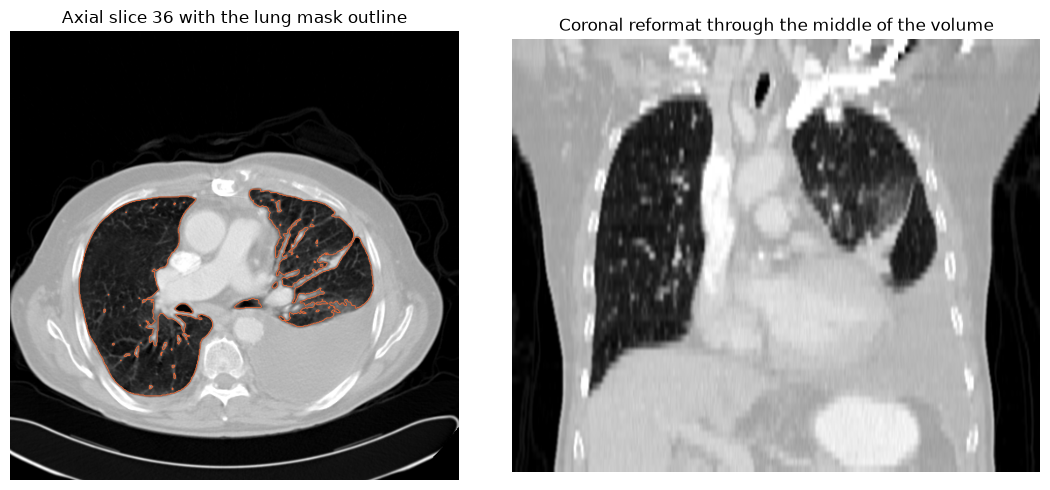

In [13]:
body = ndimage.binary_fill_holes(volume > -500, structure=np.ones((1, 3, 3)))
air_inside_body = (volume < -500) & body
labels, n_regions = ndimage.label(air_inside_body)
sizes = ndimage.sum(air_inside_body, labels, range(1, n_regions + 1))
lung = np.isin(labels, np.argsort(sizes)[::-1][:2] + 1)

lung_litres = lung.sum() * row_mm * col_mm * slice_mm / 1e6
best = int(lung.sum(axis=(1, 2)).argmax())
print(f'Approximate lung volume {lung_litres:.1f} L; slice {best} has the most lung')

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(volume[best], cmap='gray', vmin=-1000, vmax=400)
axes[0].contour(lung[best], colors='#eb6834', linewidths=0.6)
axes[0].set_title(f'Axial slice {best} with the lung mask outline')
axes[1].imshow(volume[:, volume.shape[1] // 2, :], cmap='gray', vmin=-1000, vmax=400,
               aspect=slice_mm / row_mm, origin='lower')
axes[1].set_title('Coronal reformat through the middle of the volume')
for ax in axes:
    ax.axis('off')
plt.tight_layout()

## 6. Read a whole slide image level

A DICOM whole slide image is a pyramid: one instance per resolution level, each a stack of tiles stored as frames. The `ImageType` array tells the levels apart (`VOLUME` for the pyramid, `THUMBNAIL` for a single small frame when present), and `TotalPixelMatrixColumns` and `TotalPixelMatrixRows` give the size of the level in pixels. The full resolution level of this slide is hundreds of megabytes, but the lowest level is about a megabyte, so we query the levels and fetch only the smallest one.

In [14]:
levels = run_query(f'''
SELECT ImageType,
  TotalPixelMatrixColumns AS columns_px,
  TotalPixelMatrixRows AS rows_px,
  CAST(NumberOfFrames AS INT64) AS frames,
  ROUND(instance_size / 1e6, 2) AS megabytes,
  TransferSyntaxUID,
  aws_url
FROM `bigquery-public-data.idc_current.dicom_all`
WHERE crdc_series_uuid = '{slide.crdc_series_uuid}'
ORDER BY columns_px DESC
''')
levels

,ImageType,columns_px,rows_px,frames,megabytes,TransferSyntaxUID,aws_url
0,"[DERIVED, PRIMARY, VOLUME, NONE]",110313,74849,126283,335.56,1.2.840.10008.1.2.4.91,s3://idc-open-data/8d88657b-8b57-4f8c-b474-70b4f7c9f34d/5da60a49-125a-47e9-9...
1,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",27578,18712,7992,40.57,1.2.840.10008.1.2.4.91,s3://idc-open-data/8d88657b-8b57-4f8c-b474-70b4f7c9f34d/e783efe4-d478-4b4a-a...
2,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",6894,4678,513,3.42,1.2.840.10008.1.2.4.91,s3://idc-open-data/8d88657b-8b57-4f8c-b474-70b4f7c9f34d/f2339c9a-f597-4013-9...
3,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",3447,2339,140,1.13,1.2.840.10008.1.2.4.91,s3://idc-open-data/8d88657b-8b57-4f8c-b474-70b4f7c9f34d/640f6e9d-a62e-40f6-8...
4,"[DERIVED, PRIMARY, THUMBNAIL, RESAMPLED]",1024,694,1,2.43,1.2.840.10008.1.2.1,s3://idc-open-data/8d88657b-8b57-4f8c-b474-70b4f7c9f34d/f87a5ee1-054b-48b8-8...


Tiles of a `TILED_FULL` level are stored row by row, so frame `i` sits at row `i // n_tile_columns` and column `i % n_tile_columns` of the tile grid. The `PhotometricInterpretation` of these slides says `YBR_FULL_422`, which describes the color space before JPEG 2000 compression; the decoder already returns RGB, so we ask pydicom not to convert the colors again.

TILED_FULL level: 140 tiles of 256 x 256, 3447 x 2339 px, about 8.1 um per pixel


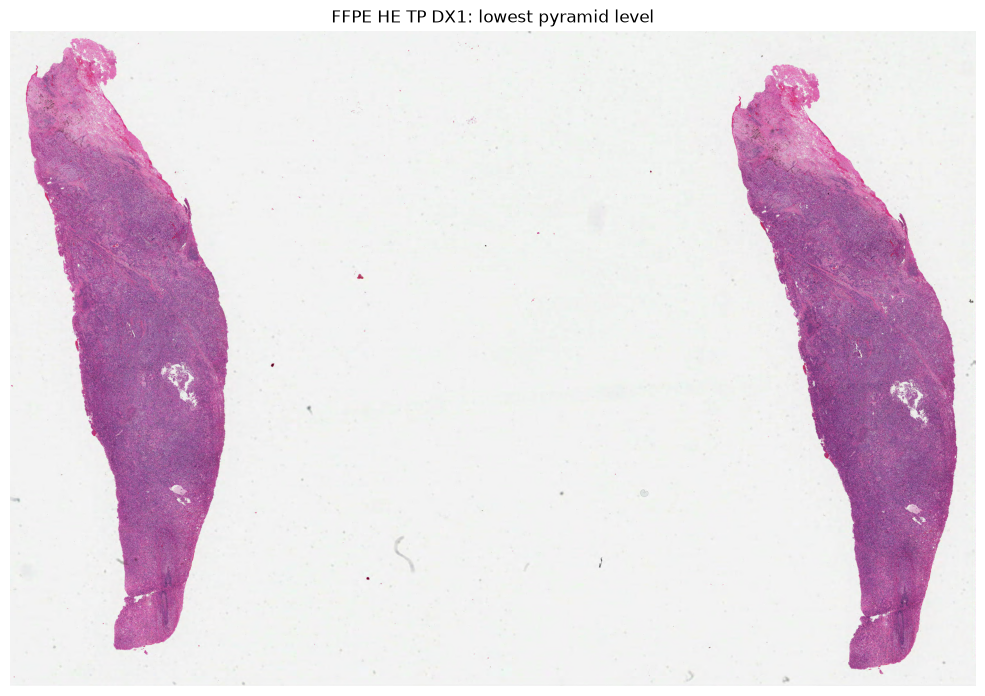

In [15]:
lowest = levels[levels.ImageType.apply(lambda t: 'VOLUME' in list(t))].iloc[-1]
level = read_dicom(lowest.aws_url)

tiles = pixel_array(level, as_rgb=False)
tile_rows, tile_cols = int(level.Rows), int(level.Columns)
width, height = int(level.TotalPixelMatrixColumns), int(level.TotalPixelMatrixRows)
n_tile_columns = -(-width // tile_cols)
n_tile_rows = -(-height // tile_rows)

mosaic = np.full((n_tile_rows * tile_rows, n_tile_columns * tile_cols, 3), 255, dtype=np.uint8)
for i, tile in enumerate(tiles):
    r, c = divmod(i, n_tile_columns)
    mosaic[r * tile_rows:(r + 1) * tile_rows, c * tile_cols:(c + 1) * tile_cols] = tile
mosaic = mosaic[:height, :width]

um_per_px = float(level.ImagedVolumeWidth) * 1000 / width
print(f'{level.DimensionOrganizationType} level: {tiles.shape[0]} tiles of {tile_rows} x {tile_cols}, '
      f'{width} x {height} px, about {um_per_px:.1f} um per pixel')

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(mosaic)
ax.set_title(f'{slide.SeriesDescription}: lowest pyramid level')
ax.axis('off')
plt.tight_layout()

## 7. Put it together

With the clinical row from Section 3 and the two images in memory, one figure shows the patient's CT, pathology, and clinical record side by side. The same pattern scales to a cohort: query the series you need in BigQuery, then read only those series from the bucket.

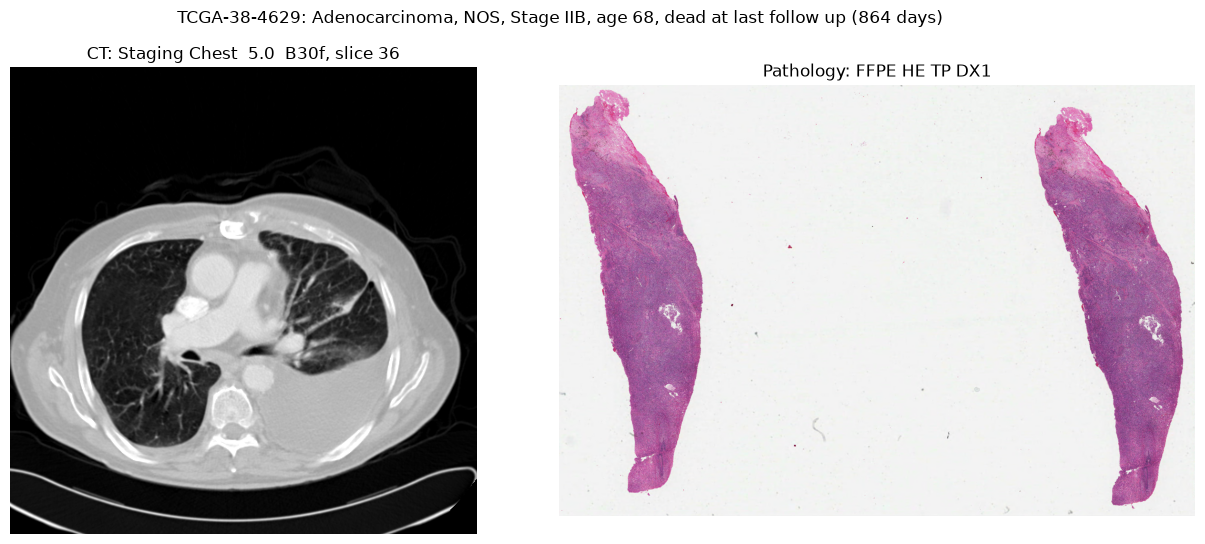

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].imshow(volume[best], cmap='gray', vmin=-1000, vmax=400)
axes[0].set_title(f'CT: {ct.SeriesDescription.strip()}, slice {best}')
axes[1].imshow(mosaic)
axes[1].set_title(f'Pathology: {slide.SeriesDescription.strip()}')
for ax in axes:
    ax.axis('off')
fig.suptitle(f'{patient_id}: {clinical_row.diagnosis}, {clinical_row.stage}, age {clinical_row.age}, '
             f'{clinical_row.vital_status.lower()} at last follow up ({clinical_row.days_to_last_follow_up:.0f} days)',
             fontsize=12)
plt.tight_layout()

## Summary

- IDC `PatientID` and GDC `submitter_id` are the same TCGA barcode, so IDC image metadata and ISB-CGC clinical tables join directly in BigQuery.
- `dicom_all` is clustered on `collection_id`; one TCGA collection scans a few megabytes.
- Every IDC instance has a public URL in `aws_url` and `gcs_url`. The buckets allow anonymous reads, so the images need no credentials and no download step beyond the series you actually use.
- Whole slide images are pyramids with one instance per level, so a quick look costs about a megabyte rather than the full slide.

### Next steps

- Change `gdc_project` and `collection_id` to another TCGA project, for example `TCGA-BRCA` and `tcga_brca`.
- For non TCGA collections, check the IDC collection page for how patient identifiers relate to GDC before joining.
- To download whole collections or many series, see the [idc-index](https://github.com/ImagingDataCommons/idc-index) package and the IDC [data access documentation](https://learn.canceridc.dev/data/downloading-data).

### Citations and links

- Fedorov A, et al. NCI Imaging Data Commons. Cancer Research 2021;81(16):4188-4193. https://doi.org/10.1158/0008-5472.CAN-21-0950
- Fedorov A, et al. National Cancer Institute Imaging Data Commons: Toward Transparency, Reproducibility, and Scalability in Imaging Artificial Intelligence. RadioGraphics 2023;43(12). https://doi.org/10.1148/rg.230180
- Reynolds SM, et al. The ISB Cancer Genomics Cloud: A Flexible Cloud-Based Platform for Cancer Genomics Research. Cancer Research 2017;77(21):e7-e10. https://doi.org/10.1158/0008-5472.CAN-17-0617
- Heath AP, et al. The NCI Genomic Data Commons. Nature Genetics 2021;53:257-262. https://doi.org/10.1038/s41588-021-00791-5
- The TCGA-LUAD image collection is cited by the `Source_DOI` printed in Section 4 and is distributed under the license printed next to it. Please cite both the collection and IDC when you use the images.